In [9]:
#Dependencies
library(ggplot2)
library(BEACON)

In [8]:
#Read in barcode count matrix from Gaublomme et al.
data_barcodes <- read.csv("barcodes_gaublomme.csv",row.names = 1)
data_barcodes <- as.matrix(data_barcodes)

In [5]:
#Read in Demuxlet assignments
labels_demuxlet <- read.csv("labels_gaublomme_demuxlet.csv",row.names=1)[,1]
names(labels_demuxlet) <- rownames(read.csv("labels_gaublomme_demuxlet.csv",row.names=1))


In [6]:
#### Run BEACON ####

#Set default parameters
params <- list()
params$sig_max <- 3 # Maximum allowable signal barcodes
params$min_count <- 2 # Minimum allowable counts for a signal barcode
params$max_bf <- 0.97 # Maximum allowable background fraction a non-negative call
params$max_iter <- 30 # Maximum number of iterations

In [10]:
#Run BEACON
labels_beacon <- beacon_calls(data_barcodes,params)

[1] "Solving initial parameters..."
[1] "Iteration 1..."
Joint log-likelihood = -59208
[1] "Iteration 2..."
Joint log-likelihood = -58572
[1] "Iteration 3..."
Joint log-likelihood = -58545
[1] "Iteration 4..."
Joint log-likelihood = -58544
[1] "Parameters converged!"


In [11]:
# Make the confusion matrix
demuxlet <- labels_demuxlet
beacon <- labels_beacon
conf_mat <- table(
  Demuxlet = demuxlet,
  BEACON = beacon
)

#Normalize by total cell number
conf_mat_norm <- conf_mat / sum(conf_mat)

#For plotting
plot_df <- as.data.frame(conf_mat_norm)
colnames(plot_df) <- c("Demuxlet","BEACON","Proportion")

#Renaming
barcode_names <- c(
  "0" = "Negative",
  "1" = "S1HuF",
  "2" = "S2HuM",
  "3" = "S3HuF",
  "4" = "S4HuM",
  "5" = "S5HuF",
  "6" = "S6HuM",
  "7" = "S7HuF",
  "8" = "S8HuM", 
  "1000" = "Doublet")

# Relabel sample identities
plot_df$Demuxlet <- barcode_names[as.character(plot_df$Demuxlet)]
plot_df$BEACON <- barcode_names[as.character(plot_df$BEACON)]

#Set sample order
sample_order <- c(
  "Negative",
  "S1HuF",
  "S2HuM",
  "S3HuF",
  "S4HuM",
  "S5HuF",
  "S6HuM",
  "S7HuF",
  "S8HuM",
  "Doublet")

plot_df$Demuxlet <- factor(
  plot_df$Demuxlet,
  levels = sample_order
)
plot_df$BEACON <- factor(
  plot_df$BEACON,
  levels = sample_order
)


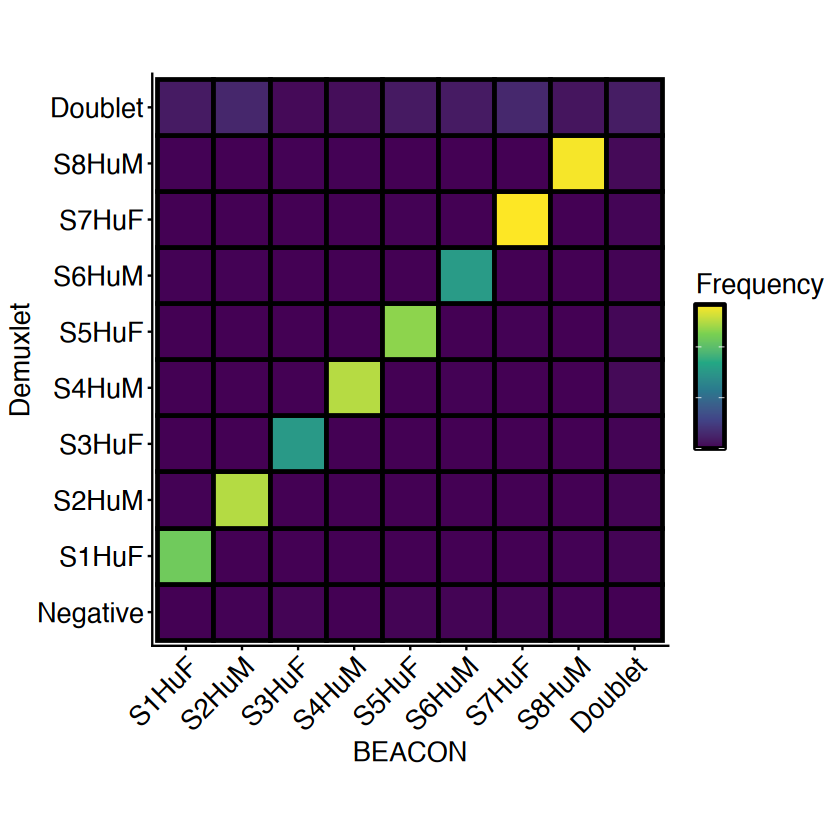

In [13]:
#Plot confusion matrix
p <- ggplot(
  plot_df,
  aes(
    x = BEACON,
    y = Demuxlet,
    fill = Proportion
  )
) +
  geom_tile(
    color = "black",
    linewidth = 1
  ) +
  scale_fill_viridis_c(
    option = "viridis",
    name = "Frequency",
    guide = guide_colourbar(
      frame.colour = "black",
      frame.linewidth = 1,
      ticks = FALSE
    )
  ) +
  coord_fixed() +
  labs(
    x = "BEACON",
    y = "Demuxlet"
  ) +
  theme_classic() +
  theme(
    axis.text.x = element_text(
      size = 16,
      angle = 45,
      hjust = 1
    ),
    axis.text.y = element_text(
      size = 16
    ),
    axis.title = element_text(
      size = 16
    ),
    legend.title = element_text(
      size = 16
    ),
    legend.text = element_blank()
  )
print(p)
